# 신경망 모델 훈련 (파이토치)

<table align="left"><tr><td>
<a href="https://colab.research.google.com/github/rickiepark/hg-mldl2/blob/main/07-3.pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="코랩에서 실행하기"/></a>
</td></tr></table>

In [1]:
# 실행마다 동일한 결과를 얻기 위해 파이토치에 랜덤 시드를 지정하고 GPU 연산을 결정적으로 만듭니다.
import torch

torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)
    torch.backends.cudnn.deterministic = True

In [2]:
from torchvision.datasets import FashionMNIST

fm_train = FashionMNIST(root='.', train=True, download=True)
fm_test = FashionMNIST(root='.', train=False, download=True)

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 212kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.92MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 25.0MB/s]


In [3]:
train_input = fm_train.data
train_target = fm_train.targets

In [4]:
train_scaled = train_input / 255.0

In [5]:
from sklearn.model_selection import train_test_split

train_scaled, val_scaled, train_target, val_target = train_test_split(
    train_scaled, train_target, test_size=0.2, random_state=42)

In [6]:
import torch.nn as nn

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 100),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(100, 10)
)

In [7]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=100, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.3, inplace=False)
  (4): Linear(in_features=100, out_features=10, bias=True)
)

In [8]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters())

In [9]:
train_hist = []
val_hist = []
patience = 2
best_loss = -1
early_stopping_counter = 0

epochs = 20
batches = int(len(train_scaled)/32)
for epoch in range(epochs):
    model.train()
    train_loss = 0
    for i in range(batches):
        inputs = train_scaled[i*32:(i+1)*32].to(device)
        targets = train_target[i*32:(i+1)*32].to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    model.eval()
    val_loss = 0
    with torch.no_grad():
        val_scaled = val_scaled.to(device)
        val_target = val_target.to(device)
        outputs = model(val_scaled)
        loss = criterion(outputs, val_target)
        val_loss = loss.item()

    train_hist.append(train_loss/batches)
    val_hist.append(val_loss)
    print(f"에포크:{epoch+1},",
          f"훈련 손실:{train_loss/batches:.4f}, 검증 손실:{val_loss:.4f}")

    if best_loss == -1 or val_loss < best_loss:
        best_loss = val_loss
        early_stopping_counter = 0
        torch.save(model.state_dict(), 'best_model.pt')
    else:
        early_stopping_counter += 1
        if early_stopping_counter >= patience:
            print(f"{epoch+1}번째 에포크에서 조기 종료되었습니다.")
            break

에포크:1, 훈련 손실:0.6031, 검증 손실:0.4344
에포크:2, 훈련 손실:0.4415, 검증 손실:0.3981
에포크:3, 훈련 손실:0.4023, 검증 손실:0.3699
에포크:4, 훈련 손실:0.3820, 검증 손실:0.3614
에포크:5, 훈련 손실:0.3675, 검증 손실:0.3564
에포크:6, 훈련 손실:0.3539, 검증 손실:0.3468
에포크:7, 훈련 손실:0.3432, 검증 손실:0.3410
에포크:8, 훈련 손실:0.3357, 검증 손실:0.3315
에포크:9, 훈련 손실:0.3261, 검증 손실:0.3335
에포크:10, 훈련 손실:0.3201, 검증 손실:0.3335
10번째 에포크에서 조기 종료되었습니다.


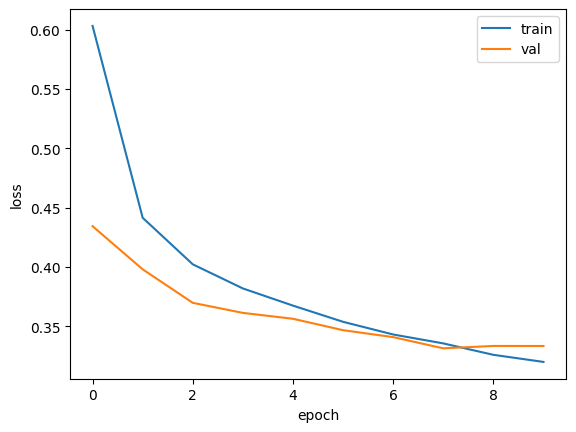

In [10]:
import matplotlib.pyplot as plt

plt.plot(train_hist, label='train')
plt.plot(val_hist, label='val')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend()
plt.show()

In [11]:
model.load_state_dict(torch.load('best_model.pt', weights_only=True))

<All keys matched successfully>

In [12]:
model.eval()
with torch.no_grad():
    val_scaled = val_scaled.to(device)
    val_target = val_target.to(device)
    outputs = model(val_scaled)
    predicts = torch.argmax(outputs, 1)
    corrects = (predicts == val_target).sum().item()

accuracy = corrects / len(val_target)
print(f"검증 정확도: {accuracy:.4f}")

검증 정확도: 0.8798


과제

에포크:1 {'train_running': 0.6031, 'train_end_dropout': 0.4496, 'train_end_eval': 0.4167, 'val': 0.4344}
에포크:2 {'train_running': 0.4409, 'train_end_dropout': 0.4024, 'train_end_eval': 0.3672, 'val': 0.3908}
에포크:3 {'train_running': 0.4047, 'train_end_dropout': 0.3826, 'train_end_eval': 0.3459, 'val': 0.376}
에포크:4 {'train_running': 0.3839, 'train_end_dropout': 0.3585, 'train_end_eval': 0.3215, 'val': 0.356}
에포크:5 {'train_running': 0.368, 'train_end_dropout': 0.3714, 'train_end_eval': 0.3264, 'val': 0.3653}
에포크:6 {'train_running': 0.3545, 'train_end_dropout': 0.3495, 'train_end_eval': 0.3108, 'val': 0.3564}
에포크:7 {'train_running': 0.3455, 'train_end_dropout': 0.3372, 'train_end_eval': 0.2971, 'val': 0.348}
에포크:8 {'train_running': 0.3393, 'train_end_dropout': 0.3362, 'train_end_eval': 0.2894, 'val': 0.3455}
에포크:9 {'train_running': 0.3276, 'train_end_dropout': 0.315, 'train_end_eval': 0.2748, 'val': 0.3315}
에포크:10 {'train_running': 0.3223, 'train_end_dropout': 0.3095, 'train_end_eval': 0.2664,

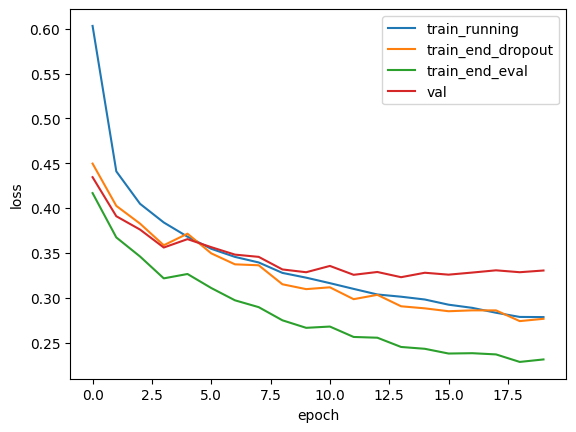

In [14]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# 이전 셀에서 이미 학습된 가중치로 이어서 돌지 않도록 모델을 새로 만듦
torch.manual_seed(42)
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 100),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(100, 10)
).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters())

train_scaled, train_target = train_scaled.to(device), train_target.to(device)
val_scaled, val_target = val_scaled.to(device), val_target.to(device)

def full_loss(x, y, dropout_on):
    """현재 가중치 고정, 데이터 전체 loss (dropout on/off만 선택)"""
    model.train() if dropout_on else model.eval()
    with torch.no_grad():
        return criterion(model(x), y).item()

hist = {'train_running': [], 'train_end_dropout': [], 'train_end_eval': [], 'val': []}

epochs = 20
batches = int(len(train_scaled)/32)
for epoch in range(epochs):
    model.train()
    train_loss = 0
    for i in range(batches):
        inputs = train_scaled[i*32:(i+1)*32]
        targets = train_target[i*32:(i+1)*32]
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    hist['train_running'].append(train_loss/batches)                               # ① 학습 중 평균, dropout ON
    hist['train_end_dropout'].append(full_loss(train_scaled, train_target, True))   # ② epoch 끝, dropout ON
    hist['train_end_eval'].append(full_loss(train_scaled, train_target, False))     # ③ epoch 끝, dropout OFF
    hist['val'].append(full_loss(val_scaled, val_target, False))                    # ④ val

    print(f"에포크:{epoch+1}", {k: round(v[-1], 4) for k, v in hist.items()})

for k, v in hist.items():
    plt.plot(v, label=k)
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend()
plt.show()